# Машинное обучение, ФКН ВШЭ

## Практическое задание 5. Решающие деревья

### Общая информация
Дата выдачи: 29.11.2023

Мягий дедлайн: 23:59 12.12.2023

Жестокий дедлайн: 23:59 14.12.2023

### О задании

Задание состоит из двух разделов:
1. В первом разделе вы научитесь применять деревья из sklearn для задачи классификации. Вы посмотрите какие разделяющие поверхности деревья строят для различных датасетов и проанализируете их зависимость от различных гиперпараметров.
2. Во втором разделе вы попробуете реализовать свое решающее дерево и сравните его со стандартное имплиментацией из sklearn. Вы также протестируете деревья на более сложных датасетах и сравните различные подходы к кодированию категориальных признаков.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.


### Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-05-trees-Username.ipynb
* Модуль hw5code.py
* Ссылки на посылки в Яндекс.Контесте для обеих задач

В контест https://contest.yandex.ru/contest/56884/problems/ нужно отправить файл hw5code.py с реализованными функциями и классами.

Username — ваша фамилия и имя на латинице именно в таком порядке

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже:

__Оценка:__

In [410]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import Colormap, ListedColormap
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
sns.set(style='whitegrid')

import warnings
warnings.filterwarnings('ignore')

# 1. Решающие деревья. Визуализация.

В этой части мы рассмотрим два простых двумерных датасета сделанных с помощью `make_moons`, `make_circles` и посмотрим как ведет себя разделяющая поверхность в зависимости от различных гиперпараметров.

In [411]:
from sklearn.datasets import make_moons, make_circles, make_classification
datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2, class_sep=.8, random_state=3,
                        n_redundant=0, )
]

In [412]:
palette = sns.color_palette(n_colors=3)
cmap = ListedColormap(palette)

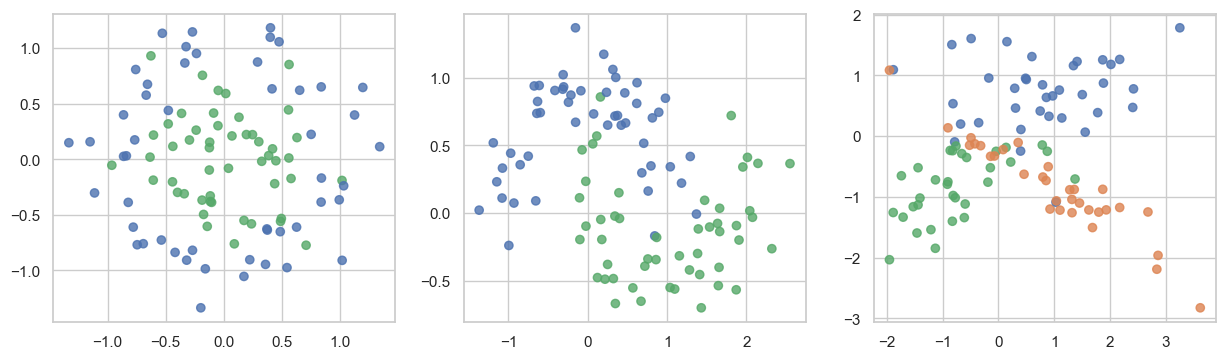

In [413]:
plt.figure(figsize=(15, 4))
for i, (x, y) in enumerate(datasets):
    plt.subplot(1, 3, i + 1)
    plt.scatter(x[:, 0], x[:, 1], c=y, cmap=cmap, alpha=.8)

__Задание 1. (1 балл)__

Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделящие поверхности (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках. Сильно ли деревья переобучились?

In [414]:
def plot_surface(clf, X, y):
    plot_step = 0.01
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap = ListedColormap(palette)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.3)

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, alpha=.7,
                edgecolors=np.array(palette)[y], linewidths=2)

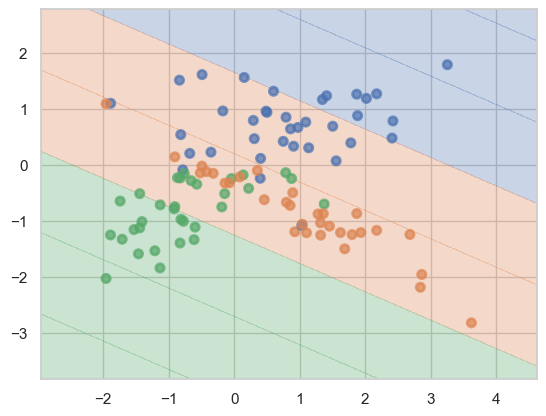

In [415]:
# Пример:
from sklearn.linear_model import LinearRegression
X, y = datasets[2]
lr  = LinearRegression().fit(X, y)
plot_surface(lr, X, y)

Accuracy (train): 1.0
Accuracy (test): 0.8
Accuracy (train): 1.0
Accuracy (test): 0.9666666666666667
Accuracy (train): 1.0
Accuracy (test): 0.9


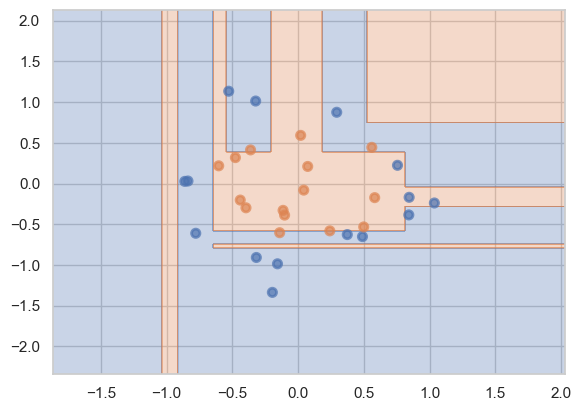

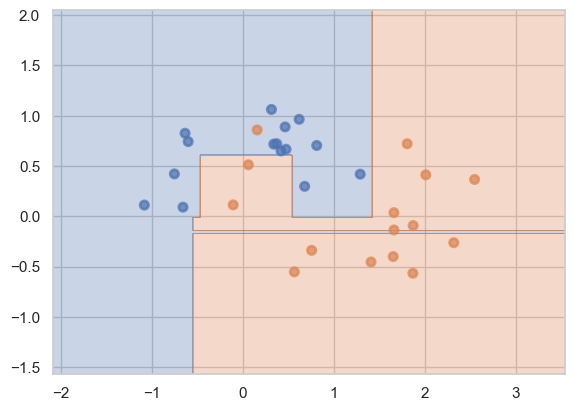

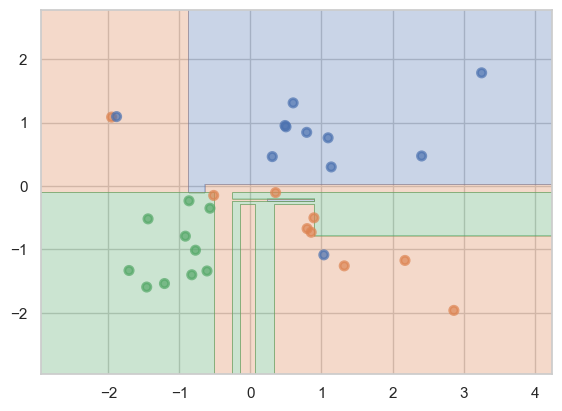

In [416]:
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
for i in datasets:
    fig,ax = plt.subplots()
    X, y = i[0], i[1]
    X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3)
    model = DecisionTreeClassifier().fit(X_train, y_train)
    plot_surface(model, X_test, y_test)
    print("Accuracy (train):", accuracy_score(y_train, model.predict(X_train)))
    print("Accuracy (test):", accuracy_score(y_test, model.predict(X_test)))


__Ответ:__ Сильно переобучились (большое количество плоскостей, accuracy = 1 на тестовой выборке)

__Задание 2. (1.5 балла)__

Попробуйте перебрать несколько параметров для регуляризации (напр. `max_depth`, `min_samples_leaf`). Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки. Можно делать кросс-валидацию или просто разбиение на трейн и тест, главное делайте каждый раз одинаковое разбиение, чтобы можно было корректно сравнивать (помните же, что итоговое дерево сильно зависит от небольшого изменения обучающей выборки?). Проследите как меняется разделяющая поверхность и обобщающая способность. Почему так происходит, одинаково ли изменение для разных датасетов?

In [417]:
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from sklearn.model_selection import GridSearchCV

X, y = datasets[2][0], datasets[2][1]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.3, random_state=42
)

model = DecisionTreeClassifier()
gscv = GridSearchCV(
    estimator=model,
    param_grid={
        'max_depth' : np.arange(5, 10, 1),
        'min_samples_leaf': np.arange(10, 20, 2)
    },
    cv=5, scoring='accuracy'
)
gscv.fit(X_train, y_train)

df_params = pd.DataFrame(gscv.cv_results_['params'])
df_params['mean_test_score'] = gscv.cv_results_['mean_test_score']
df_params = df_params.sort_values('mean_test_score', ascending=False)

#print(f"Best Parameters: {gscv.best_params_}")
#print(f"Best CV Score: {gscv.best_score_:.4f}")
print(df_params.head(5))

    max_depth  min_samples_leaf  mean_test_score
0           5                10         0.785714
1           5                12         0.785714
23          9                16         0.785714
22          9                14         0.785714
21          9                12         0.785714


__Ответ:__ Обобщающая способность падает с глубиной дерева и увеличивается с минимальным количеством сэмплов в листе

# 2. Решающие деревья своими руками

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__Задание 3. (1.5 балл)__

Реализуйте функцию find_best_split из модуля hw5code.py

готово

__Задание 4. (0.5 балла)__

Загрузите таблицу [students.csv](https://github.com/esokolov/ml-course-hse/blob/master/2022-fall/homeworks-practice/homework-practice-05-trees/students.csv) (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

In [418]:
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
df = pd.read_csv("./students.csv")
print(df.head(2))
print(df.shape)

    STG   SCG  STR   LPR  PEG  UNS
0  0.00  0.00  0.0  0.00  0.0    0
1  0.08  0.08  0.1  0.24  0.9    1
(258, 6)


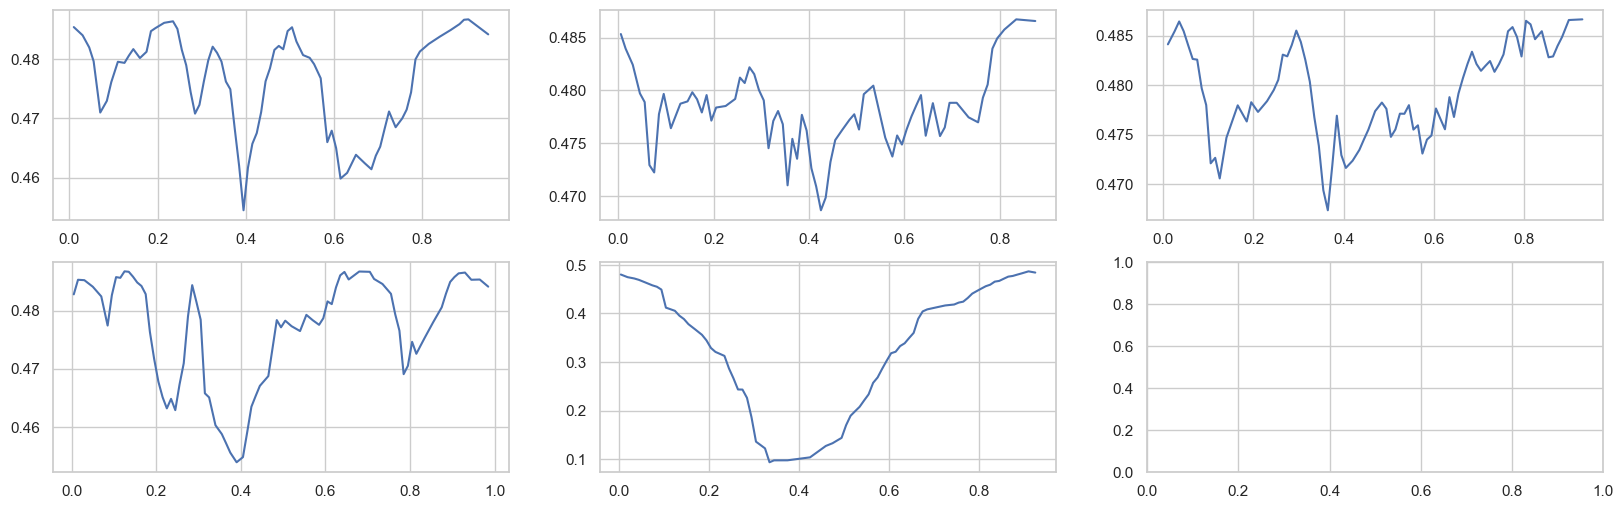

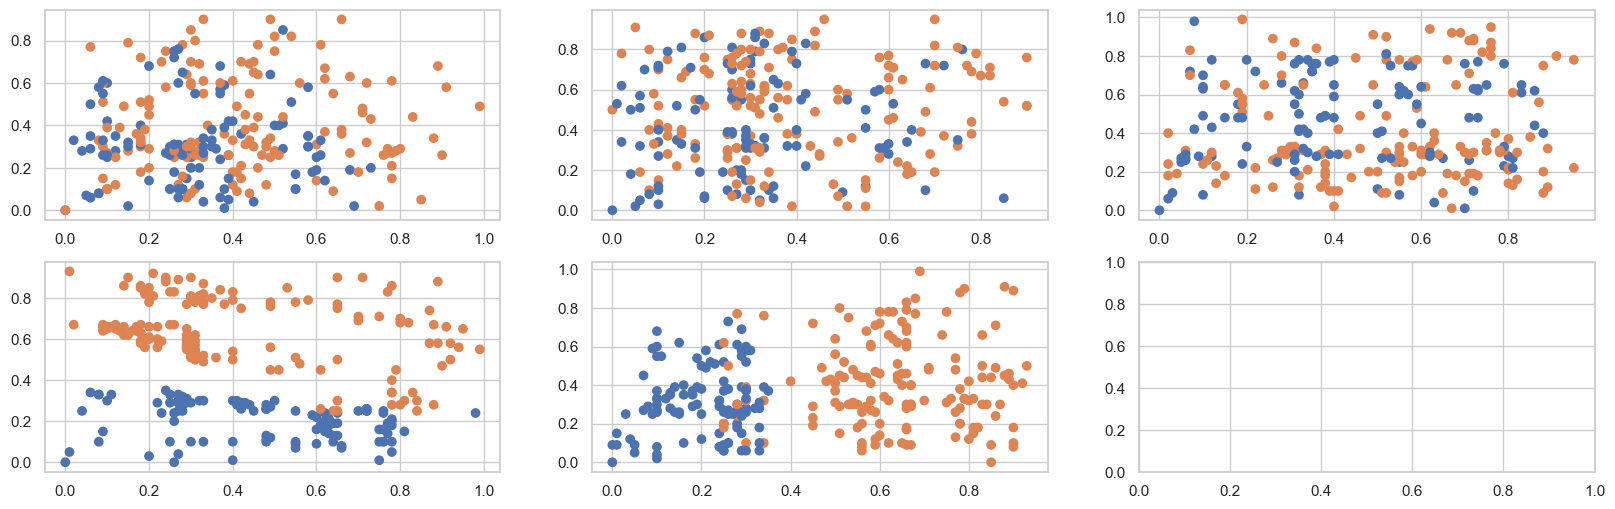

In [419]:
"""
Old O(N ** 2) implementation. Spent a lot of time on it :(

def gini(feature_vector, target_vector):
    X, y = feature_vector, target_vector

    #Sorting by (x, y)
    cur = np.stack([X, y], axis=1)
    sort_idx = cur[:, 0].argsort()
    X, y = X[sort_idx], y[sort_idx]

    thresholds = (X[:-1] + X[1:]) / 2
    xx, yy = np.meshgrid(X, thresholds)
    mask = xx > yy # Making split

    cnt = len(y) - mask.sum(axis=1) #Number of elements (left part)
    zz = np.meshgrid(y, thresholds)[0]
    mask2 = np.array(mask == zz) #True if predction = label

    p = mask2.cumsum(axis=1) #Prefix sum to calculate left part
    temp = np.diag(p[np.ix_(np.arange(0, len(thresholds), 1), cnt - 1)]) #To extract prefix sums for left partss
    sums = mask2.sum(axis=1) #Total number of true predictions

    pref_p = (temp / cnt) #Probs for left part
    pref_gini = (1 - pref_p ** 2 - (1 - pref_p) ** 2) * (cnt / len(y))
    suf_p = ( (sums - temp) / (len(y) - cnt) )
    suf_gini = (1 - suf_p ** 2 - (1 - suf_p) ** 2) * ((len(y) - cnt) / len(y))

    total_gini = pref_gini + suf_gini

    return thresholds, total_gini
"""

def gini(feature_vector, target_vector, min_samples_leaf=None):
    X, y = feature_vector, target_vector

    #Sorting by (x, y)
    cur = np.stack([X, y], axis=1)
    sort_idx = cur[:, 0].argsort()
    X, y = X[sort_idx], y[sort_idx]

    #Split only for different values
    split = (X[1:] != X[:-1])

    #Len of parts
    pref = np.arange(1, len(X), 1)
    suf = np.arange(len(X) - 1, 0, -1)

    if min_samples_leaf is not None:
        mask = (pref > min_samples_leaf) & (suf > min_samples_leaf)
        split = mask & split

    left_ones = np.cumsum(y == 1)
    right_ones = (y == 1).sum() - left_ones

    #Proportions
    left_p = left_ones[:-1] / pref
    right_p = right_ones[1:] / suf

    #Gini calculation
    pref_p = pref / len(X)
    pref_gini = pref_p * (1 - left_p ** 2 - (1 - left_p) ** 2)
    suf_gini = (1 - pref_p) * (1 - right_p ** 2 - (1 - right_p) ** 2)
    gini_total = pref_gini + suf_gini

    gini_total = gini_total[split]
    thresholds = (X[1:] + X[:-1])[split] / 2

    if len(gini_total) == 0:
        return None, None, None, None
    
    best_idx = np.argmin(gini_total)

    return thresholds, gini_total

fig, ax = plt.subplots(2, 3, figsize=(20, 6))

for i in range(df.shape[1] - 1):
    axis = ax[i // 3][i % 3]
    thresholds, total_gini = gini(np.array(df.iloc[:, i]), np.array(df.iloc[:, 5]))
    #plt.scatter()

    axis.plot(thresholds, total_gini)
    #print(thresholds)

palette = sns.color_palette(n_colors=2)
cmap = ListedColormap(palette)

fig, ax = plt.subplots(2, 3, figsize=(20, 6))
for i in range(df.shape[1] - 1):
    axis = ax[i // 3][i % 3]

    axis.scatter(
        np.array(df.iloc[:, i]), np.array(df.iloc[:, (i + 1) % 5]), c = np.array(df.iloc[:, 5]),
        cmap = cmap
    )
    #print(thresholds)

__Задание 5. (0.5 балла)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ:**
По признаку PEG. Результат scatter согласуется с результатом gini. Для почти идеальных график выглядит как вогнутая вниз кривая. Для почти невозможных gini колеблется около прямой

__Задание 6. (1.5 балла).__

Разберитесь с уже написанным кодом в классе DecisionTree модуля hw5code.py. Найдите ошибки в реализации метода \_fit_node. Напишите функцию \_predict_node.

 Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в [лекции](https://github.com/esokolov/ml-course-hse/blob/master/2020-fall/lecture-notes/lecture07-trees.pdf) в разделе «Построение дерева». Выбор лучшего разбиения необходимо производить по критерию Джини. Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку. Ответ в листе: наиболее часто встречающийся класс в листе. Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

__Задание 7. (0.5 балла)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (лежит на гитхабе вместе с заданием), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [420]:
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder

df = pd.read_csv('agaricus-lepiota.data')
X = df.copy()
X['p'] = (X['p'] == 'e')
y = X['p']
X = X.drop(columns=["p"])

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.5)

In [421]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [422]:
%autoreload 2

from hw5code import DecisionTree

types = ["categorical"] * X_train.shape[1]
model = DecisionTree(feature_types=types, max_depth=10)

X_train, y_train = np.array(X_train), np.array(y_train)
model.fit(np.array(X_train), np.array(y_train))

In [423]:
from sklearn.metrics import accuracy_score

preds = model.predict(np.array(X_test))
acc = accuracy_score(y_test, preds)
print(f"Accuracy: {acc}")

Accuracy: 0.9975381585425899


__Задание 8. (бонус, 1 балл)__

Реализуйте в классе DecisionTree поддержку параметров max_depth, min_samples_split и min_samples_leaf по аналогии с DecisionTreeClassifier. Постройте графики зависимости качества предсказания в зависимости от этих параметров для набора данных tic-tac-toe (см. следующий пункт).

Реализовал, работает. Не чекал :)

__Задание 9. (2 балла)__

Загрузите следующие наборы данных (напомним, что pandas умеет загружать файлы по url, в нашем случае это файл \*.data), предварительно ознакомившись с описанием признаков и целевой переменной в каждом из них (она записаны в Data Folder, в файле *.names): 
* [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom) (загрузили в предыдущем пункте, классы записаны в нулевом столбце)
* [tic-tac-toe](https://archive.ics.uci.edu/ml/datasets/Tic-Tac-Toe+Endgame) (классы записаны в последнем столбце, датасет лежит на гитхабе вместе с заданием)
* [cars](https://archive.ics.uci.edu/ml/datasets/Car+Evaluation) (классы записаны в последнем столбце, считаем что unacc, acc — это класс 0, good, vgood — класс 1)
* [nursery](https://archive.ics.uci.edu/ml/datasets/Nursery) (классы записаны в последнем столбце, считаем, что not_recom и recommend — класс 0, very_recom, priority, spec_prior — класс 1).

Закодируйте категориальные признаки, использовав LabelEncoder. С помощью cross_val_score (cv=10) оцените accuracy на каждом из этих наборов данных следующих алгоритмов:
* DecisionTree, считающий все признаки вещественными
* DecisionTree, считающий все признаки категориальными
* DecisionTree, считающий все признаки вещественными + one-hot-encoding всех признаков
* DecisionTreeClassifier из sklearn. Запишите результат в pd.DataFrame (по строкам — наборы данных, по столбцам — алгоритмы).

Рекомендации:
* Чтобы cross_val_score вычисляла точность, нужно передать scoring=make_scorer(accuracy_score), обе фукнции из sklearn.metrics.
* Если вам позволяет память (а она скорее всего позволяет), указывайте параметр sparse=False в OneHotEncoder (если вы, конечно, используете его). Иначе вам придется добиваться того, чтобы ваша реализация дерева умела работать с разреженными матрицами (что тоже, в целом, не очень сложно).

In [447]:
### ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.metrics import make_scorer
from sklearn.tree import DecisionTreeClassifier
from ucimlrepo import fetch_ucirepo 

def train_model(feature_types, res, X, y):
    model = DecisionTree(feature_types=feature_types, max_depth=10)
    acc = cross_val_score(model, np.array(X), np.array(y), scoring=make_scorer(accuracy_score), cv=10)
    res.append(acc.mean())

def make_cv_df(df_res, X, y):
    xx = X.copy()
    res = []

    ct = ColumnTransformer([
        ("cat", OrdinalEncoder(), X.columns)
    ])
    X = ct.fit_transform(X, y)
    model_sk = DecisionTreeClassifier(max_depth=10)
    acc_sk = cross_val_score(model_sk, X, y, scoring=make_scorer(accuracy_score), cv=10)

    train_model(["real"] * X.shape[1], res, X, y)
    train_model(["categorical"] * X.shape[1], res, X, y)

    X = xx
    ct = ColumnTransformer([
        ('ohe', OneHotEncoder(sparse_output=False, drop='first'), X.columns)
    ])
    X = ct.fit_transform(X, y)

    train_model(["real"] * X.shape[1], res, X, y)
    res.append(acc_sk.mean())
    df_res.loc[len(df_res)] = res


df_res = pd.DataFrame(columns=["num", "cat", "num + ohe", "sklearn"])

df = pd.read_csv("tic-tac-toe-endgame.csv")
make_cv_df(df_res, df.drop(columns=["V10"]), np.array(df["V10"] == "positive"))
df = pd.read_csv("agaricus-lepiota.data")
make_cv_df(df_res, df.drop(columns=["p"]), np.array((df['p'] == 'e')))

car_evaluation = fetch_ucirepo(id=19) 
X = car_evaluation.data.features 
y = car_evaluation.data.targets 
y = ((y == "good") | (y == "vgood")).values.ravel().astype(int)
make_cv_df(df_res, X, y)


nursery = fetch_ucirepo(id=76) 
X = nursery.data.features 
y = nursery.data.targets
y = ((y == "very_recom") | (y == "priority") | (y == "spec_prior")).values.ravel().astype(int)
make_cv_df(df_res, X, y)

print(df_res)

        num       cat  num + ohe   sklearn
0  0.420504  0.597763   0.690406  0.764386
1  0.992980  0.999507   1.000000  0.958290
2  0.926418  0.966975   0.915368  0.935771
3  0.999614  0.999846   0.999846  0.999691


__Задание 10. (1 балла)__

Проанализируйте результаты эксперимента. 
Одинаково ли для разных наборов данных ранжируются алгоритмы? 
Порассуждайте, почему так происходит. 

Обратите внимание на значение признаков в разных наборах данных. 
Присутствует ли в результатах какая-то компонента случайности? 
Можно ли повлиять на нее и улушить работу алгоритмов?

**Ответ:** Для разных датасетов точность разных методов будет разной. Разные методы решают разные задачи. Случайность кросс-валидации и порядка столбцов (тк мы берем первый сплит). Фиксировать random_state, добавить параметры min_samples_leaf, min_samples_split чтобы убрать случайный шум в маленьких листьях.

Вставьте что угодно, описывающее ваши впечатления от этого задания:

>D